In [1]:
from pathlib import Path
from urllib.request import urlopen

import polars as pl

In [2]:
URL = "https://raw.githubusercontent.com/Realbenjizo/Exploratory-Data-Analysis---Four-Must-Know-Techniques/main/humans.csv"
DEST = Path().parent / "data" / "humans.csv"

In [3]:
DEST.parent.mkdir(parents=True, exist_ok=True)
with urlopen(URL) as response, DEST.open("wb") as file:
    file.write(response.read())
print(f"Saved {DEST} ({DEST.stat().st_size} bytes)")

Saved data\humans.csv (46627 bytes)


In [4]:
DEST.parent.mkdir(parents=True, exist_ok=True)
data = pl.scan_csv(DEST)
df = data.collect()
df

Height,Weight,Age,Gender
f64,f64,i64,str
174.967142,76.996777,49,"""Male"""
168.617357,74.623168,50,"""Female"""
176.476885,70.298152,57,"""Male"""
185.230299,66.765316,30,"""Male"""
167.658466,73.491117,54,"""Female"""
…,…,…,…
167.188997,75.350751,37,"""Male"""
187.976865,69.867394,51,"""Male"""
176.408429,65.590627,57,"""Male"""


### Univariate Analysis

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

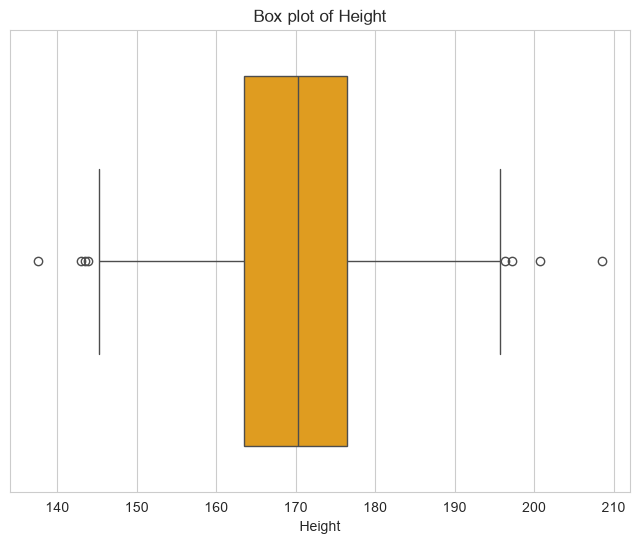

In [6]:
# Box plot of the height column
plt.figure(figsize=(8, 6))
sns.boxplot(x=df["Height"], color="orange")
plt.title("Box plot of Height")
plt.xlabel("Height")
plt.show()

### Bivariate Analysis

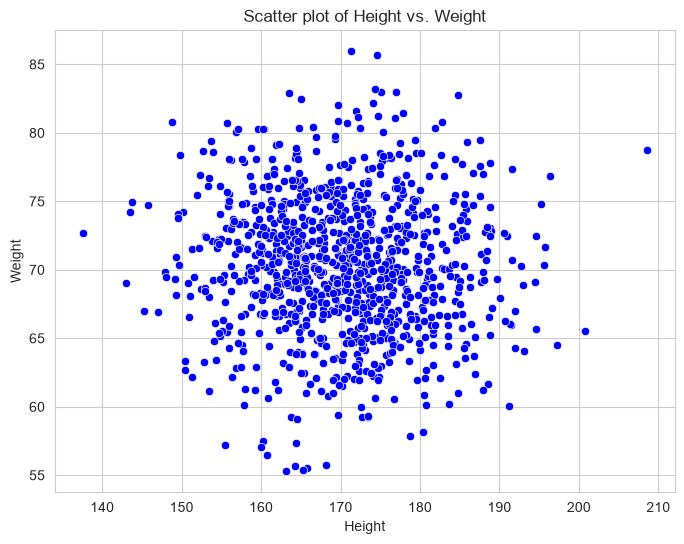

In [7]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=df["Height"], y=df["Weight"], color="blue")
plt.title("Scatter plot of Height vs. Weight")
plt.xlabel("Height")
plt.ylabel("Weight")
plt.show()

### Multivariate Analysis

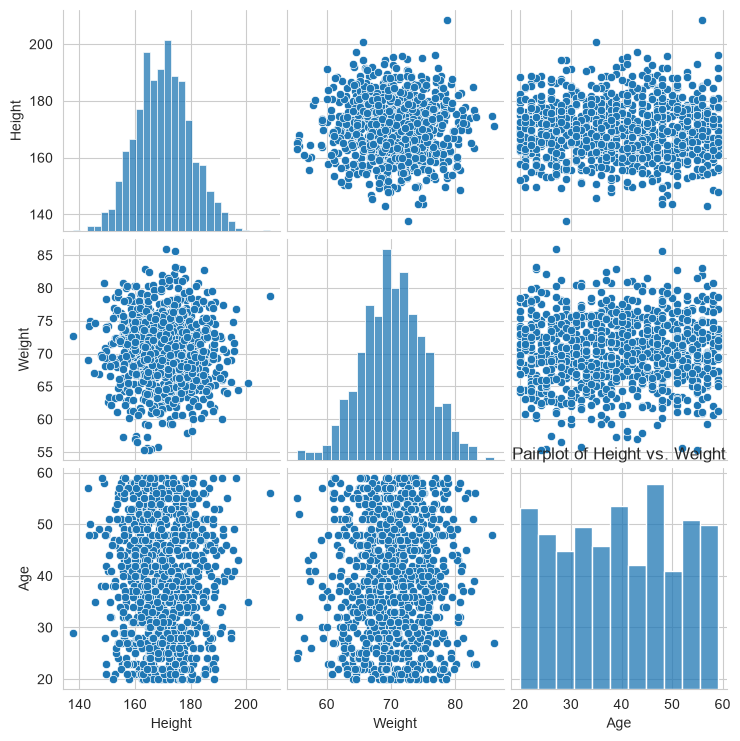

In [8]:

# Pairplot of Height, Weight and Age
sns.pairplot(df[["Height", "Weight", "Age"]].to_pandas())
plt.title("Pairplot of Height vs. Weight")
plt.show()

### Feature Engineering

In [10]:
# Creating a new variable BMI (Body Mass Index)
df = df.with_columns(
    (pl.col("Weight") / (pl.col("Height") / 100) ** 2).alias("BMI")
)
df.head()

Height,Weight,Age,Gender,BMI
f64,f64,i64,str,f64
174.967142,76.996777,49,"""Male""",25.151249
168.617357,74.623168,50,"""Female""",26.246363
176.476885,70.298152,57,"""Male""",22.571907
185.230299,66.765316,30,"""Male""",19.459284
167.658466,73.491117,54,"""Female""",26.144712


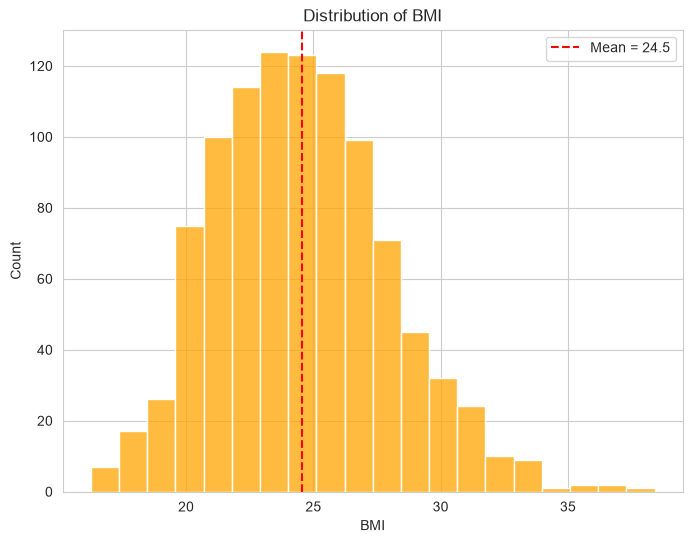

In [11]:
# Distribution of BMI
plt.figure(figsize=(8, 6))
sns.histplot(x=df["BMI"], bins=20, color="orange")
plt.axvline(df["BMI"].mean(), color="red", linestyle="--", label=f"Mean = {df['BMI'].mean():.1f}")
plt.title("Distribution of BMI")
plt.xlabel("BMI")
plt.legend()
plt.show()